In [1]:
import json
import requests

In [4]:
url = "https://jsonplaceholder.typicode.com/posts"
try:
  response = requests.get(url,timeout=15)
  response.raise_for_status()
  data = response.json()
  print("Total Posts:", len(data))
  print("First Post:",data[:5])
  for post in data[:5]:
    print("ID:",post["id"])
    print("Title:",post["title"])
    print("UsercID:",post["userId"])
    print("--------------")
except requests.exceptions.Timeout:
  print("The request timed out")
except requests.exceptions.RequestException as e:
  print("Request failed:", e)
except ValueError:
  print("Invalid JSON response")
except requests.exceptions.HTTPError as e:
  print("HTTP error:", e)

Total Posts: 100
First Post: [{'userId': 1, 'id': 1, 'title': 'sunt aut facere repellat provident occaecati excepturi optio reprehenderit', 'body': 'quia et suscipit\nsuscipit recusandae consequuntur expedita et cum\nreprehenderit molestiae ut ut quas totam\nnostrum rerum est autem sunt rem eveniet architecto'}, {'userId': 1, 'id': 2, 'title': 'qui est esse', 'body': 'est rerum tempore vitae\nsequi sint nihil reprehenderit dolor beatae ea dolores neque\nfugiat blanditiis voluptate porro vel nihil molestiae ut reiciendis\nqui aperiam non debitis possimus qui neque nisi nulla'}, {'userId': 1, 'id': 3, 'title': 'ea molestias quasi exercitationem repellat qui ipsa sit aut', 'body': 'et iusto sed quo iure\nvoluptatem occaecati omnis eligendi aut ad\nvoluptatem doloribus vel accusantium quis pariatur\nmolestiae porro eius odio et labore et velit aut'}, {'userId': 1, 'id': 4, 'title': 'eum et est occaecati', 'body': 'ullam et saepe reiciendis voluptatem adipisci\nsit amet autem assumenda prov

In [14]:
import requests
import pandas as pd

url = "https://api.open-meteo.com/v1/forecast"

param = {
    "latitude":27.49,
    "longitude":77.67,
    "current":["temperature_2m","relativehumidity_2m","apparent_temperature","windspeed_10m"],
    "hourly":["temperature_2m","relativehumidity_2m","windspeed_10m"],
    "daily":["temperature_2m_max","temperature_2m_min","sunrise","sunset"],
    "forecast_days":7,
    "timezone":"Asia/Kolkata"
}
try:
  response = requests.get(url,params=param,timeout=25)
  response.raise_for_status()
  data = response.json()

  current = data["current"]

  print("Current Weather Information:")
  print("Time:",current["time"])
  print("Temperature:",current["temperature_2m"],"C")
  print("Relative humidity:",current["relativehumidity_2m"],"%")
  print("Apparent Temperature:",current["apparent_temperature"],"C")
  print("Wind Speed:",current["windspeed_10m"],"km/h")
except requests.exceptions.RequestException as error:
  print("API request failed:",error)
except (KeyError, ValueError) as error:
  print("Unable to process API response:",error)

Current Weather Information:
Time: 2026-11-24T13:15
Temperature: 24.7 C
Relative humidity: 39 %
Apparent Temperature: 24.0 C
Wind Speed: 6.8 km/h


In [15]:
daily = data["daily"]
df = pd.DataFrame({
    "Date":daily["time"],
    "Max Temperature":daily["temperature_2m_max"],
    "Min Temperature":daily["temperature_2m_min"],
    "Sunrise":daily["sunrise"],
    "Sunset":daily["sunset"]
})
print("\nSeven-day weather forecast")
df


Seven-day weather forecast


,Date,Max Temperature,Min Temperature,Sunrise,Sunset
0,2026-11-24,25.0,13.4,2026-11-24T06:46,2026-11-24T17:24
1,2026-11-25,24.9,11.6,2026-11-25T06:47,2026-11-25T17:24
2,2026-11-26,24.6,11.5,2026-11-26T06:48,2026-11-26T17:24
3,2026-11-27,24.4,11.4,2026-11-27T06:48,2026-11-27T17:24
4,2026-11-28,24.0,11.5,2026-11-28T06:49,2026-11-28T17:24
5,2026-11-29,23.2,11.6,2026-11-29T06:50,2026-11-29T17:24
6,2026-11-30,22.5,11.4,2026-11-30T06:51,2026-11-30T17:24


In [16]:
current

{'time': '2026-11-24T13:15',
 'interval': 900,
 'temperature_2m': 24.7,
 'relativehumidity_2m': 39,
 'apparent_temperature': 24.0,
 'windspeed_10m': 6.8}

In [17]:
avg_temp = df["Max Temperature"].mean()
print("Average Temperature:",avg_temp)

Average Temperature: 24.085714285714285


In [18]:
hottest_day = df.loc[df["Max Temperature"].idxmax()]
print("Hottest day:", hottest_day["Date"])

Hottest day: 2026-11-24


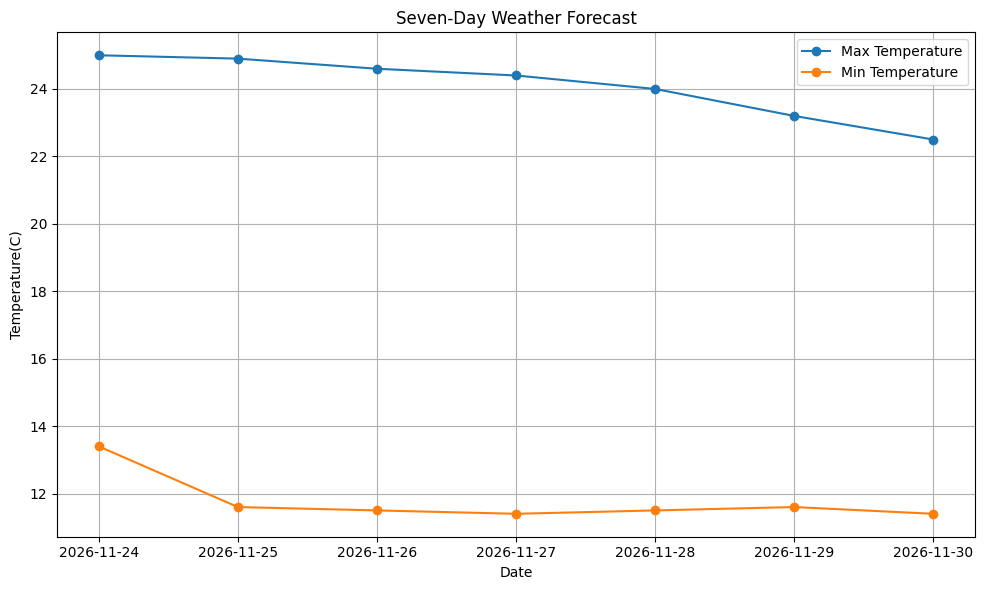

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.plot(df["Date"],df["Max Temperature"],label="Max Temperature",marker="o")
plt.plot(df["Date"],df["Min Temperature"],label="Min Temperature",marker="o")
plt.xlabel("Date")
plt.ylabel("Temperature(C)")
plt.title("Seven-Day Weather Forecast")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://api.tvmaze.com/search/shows"
params = {
    "q": "office"
}
response = requests.get(url, params=params, timeout=25)

if response.status_code == 200:
    data = response.json()
    movies = []
    for item in data:
        show = item["show"]
        movies.append({
            "Name": show["name"],
            "Language": show["language"],
            "Genres": ",".join(show["genres"]),
            "Rating": show["rating"]["average"],
            "Summary": show["summary"]
        })
    df = pd.DataFrame(movies)
else:
    print("Request failed:", response.status_code)

In [31]:
df

,Name,Language,Genres,Rating,Summary
0,The Office,English,Comedy,8.5,"<p>Steve Carell stars in <b>The Office</b>, a ..."
1,The Office,English,Comedy,7.9,<p>A mockumentary about life in a mid-sized su...
2,Death Office,Japanese,"Drama,Anime,Fantasy",NaN,"<p>All people get into the ""Death Office"" afte..."
3,Radiant Office,Korean,"Drama,Comedy,Romance",6.7,<p>Eun Ho Won faces repeat rejections in her j...
4,The Office,English,Comedy,4.9,"<p>In <b>The Office Australia</b>, Hannah Howa..."
5,Office Watch,Korean,"Drama,Comedy,Romance",NaN,<p><b>Office Watch</b> is about what goes on i...
6,The Office,Hindi,Comedy,NaN,<p>With downsizing and mediocrity as constants...
7,The Office,English,Comedy,NaN,<p>An office comedy version of the British ser...
8,Box Office,English,,NaN,"<p>Hosted by cinema enthusiast Lisa Cannon, <b..."
9,The Office PL,Polish,Comedy,NaN,"<p>The action takes place in Siedlce, at the h..."


In [28]:
movies = []
for item in data:
  show = item["show"]
  movies.append({
      "Name":show["name"],
      "Language":show["language"],
      "Genres":",".join(show["genres"]),
      "Rating": show["rating"]["average"],
      "Summary":show["summary"]
  })
  df = pd.DataFrame(movies)
else:
  print("Request failed:",response.status_code)

Request failed: 200


In [29]:
df

,Name,Language,Genres,Rating,Summary
0,The Office,English,Comedy,8.5,"<p>Steve Carell stars in <b>The Office</b>, a ..."
1,The Office,English,Comedy,7.9,<p>A mockumentary about life in a mid-sized su...
2,Death Office,Japanese,"Drama,Anime,Fantasy",NaN,"<p>All people get into the ""Death Office"" afte..."
3,Radiant Office,Korean,"Drama,Comedy,Romance",6.7,<p>Eun Ho Won faces repeat rejections in her j...
4,The Office,English,Comedy,4.9,"<p>In <b>The Office Australia</b>, Hannah Howa..."
5,Office Watch,Korean,"Drama,Comedy,Romance",NaN,<p><b>Office Watch</b> is about what goes on i...
6,The Office,Hindi,Comedy,NaN,<p>With downsizing and mediocrity as constants...
7,The Office,English,Comedy,NaN,<p>An office comedy version of the British ser...
8,Box Office,English,,NaN,"<p>Hosted by cinema enthusiast Lisa Cannon, <b..."
9,The Office PL,Polish,Comedy,NaN,"<p>The action takes place in Siedlce, at the h..."


In [32]:
valid_rating = df.dropna(subset=["Rating"])
if not valid_rating.empty:
  avg_rating = valid_rating["Rating"].mean()
  print("Average Rating:",avg_rating)
  highest = valid_rating.loc[valid_rating["Rating"].idxmax()]
  print("Highest Rating:")
  print("Name:",highest["Name"])
  print("Language:",highest["Language"])
  print("Genres:",highest["Genres"])
  print("Summary:",highest["Summary"])
else:
  print("No valid ratings available")

Average Rating: 7.0
Highest Rating:
Name: The Office
Language: English
Genres: Comedy
Summary: <p>Steve Carell stars in <b>The Office</b>, a fresh and funny mockumentary-style glimpse into the daily interactions of the eccentric workers at the Dunder Mifflin paper supply company. Based on the smash-hit British series of the same name and adapted for American Television by Greg Daniels, this fast-paced comedy parodies contemporary American water-cooler culture. Earnest but clueless regional manager Michael Scott believes himself to be an exceptional boss and mentor, but actually receives more eye-rolls than respect from his oddball staff.</p>


In [33]:
print(df[df["Rating"]>7])

         Name Language  Genres  Rating  \
0  The Office  English  Comedy     8.5   
1  The Office  English  Comedy     7.9   

                                             Summary  
0  <p>Steve Carell stars in <b>The Office</b>, a ...  
1  <p>A mockumentary about life in a mid-sized su...  
